# Week 8 – Linear Regression: House Price Prediction
**AI/ML Internship | Practical Assignment**

This notebook implements feature selection, an 80:20 train-test split, model training, prediction, and MAE/MSE/RMSE/R² evaluation.

> **Dataset notice:** The 600-row housing dataset is synthetic and intended for learning. It is not real property-market data.

## 1. Import libraries and load data
We use Pandas for tabular data, Matplotlib for diagnostics, and scikit-learn for the regression pipeline and evaluation.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.linear_regression import load_data, train_and_evaluate, FEATURES, TARGET
df = load_data(ROOT / "data" / "house_prices_synthetic.csv")
print("Dataset shape:", df.shape)
display(df.head())
display(df.describe().round(2))

Dataset shape: (600, 7)


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking_spaces,price_lakhs
0,1628,3,1,18,23.30,1,77.48
1,1063,2,1,28,3.26,2,59.13
2,1815,4,3,8,24.86,0,113.18
3,1895,3,2,14,19.48,0,106.10
4,681,1,1,17,3.24,2,79.61


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking_spaces,price_lakhs
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,1489.60,2.74,1.79,21.30,13.08,0.97,93.09
std,407.50,0.96,0.76,12.99,6.87,0.81,29.89
min,500.00,1.00,1.00,0.00,1.06,0.00,18.00
25%,1206.75,2.00,1.00,10.00,7.18,0.00,73.39
50%,1491.00,3.00,2.00,21.00,13.14,1.00,93.34
75%,1746.50,3.00,2.00,32.00,19.09,2.00,112.15
max,2724.00,6.00,4.00,44.00,24.99,2.00,187.25


## 2. Feature selection
The six property attributes are input features (`X`); `price_lakhs` is the continuous target (`y`).

In [2]:
X = df[FEATURES]
y = df[TARGET]
print("Features:", FEATURES)
print("Target:", TARGET)
print("Missing values by column:")
display(df.isna().sum())

Features: ['area_sqft', 'bedrooms', 'bathrooms', 'property_age_years', 'distance_to_city_km', 'parking_spaces']
Target: price_lakhs
Missing values by column:


area_sqft              0
bedrooms               0
bathrooms              0
property_age_years     0
distance_to_city_km    0
parking_spaces         0
price_lakhs            0
dtype: int64

## 3. Exploratory plots
These charts provide a quick view of the target and relationships. They are descriptive, not proof of causation.

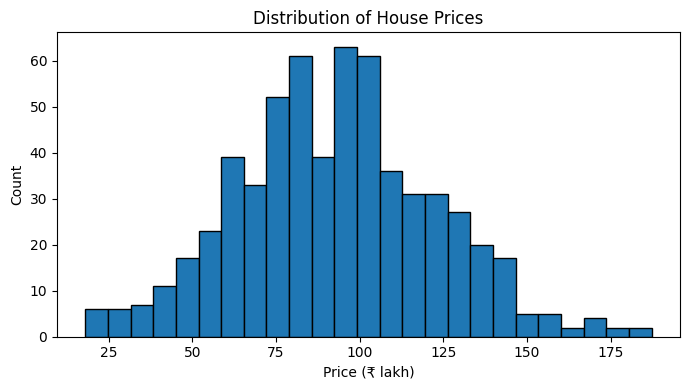

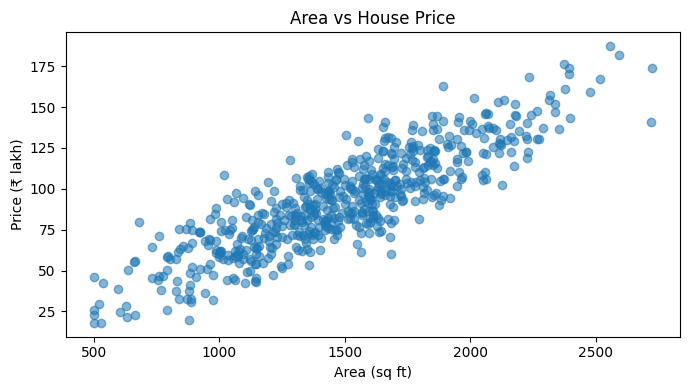

In [3]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(df[TARGET], bins=25, edgecolor="black")
ax.set(title="Distribution of House Prices", xlabel="Price (₹ lakh)", ylabel="Count")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(df["area_sqft"], df[TARGET], alpha=.55)
ax.set(title="Area vs House Price", xlabel="Area (sq ft)", ylabel="Price (₹ lakh)")
plt.tight_layout(); plt.show()

## 4. Train-test split and pipeline
We reserve 20% of rows for testing. Median imputation and standardization are fitted inside a pipeline, preventing the test set from influencing preprocessing.

In [4]:
pipeline, X_train, X_test, y_train, y_test, y_pred, metrics = train_and_evaluate(df)
print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")
print("Evaluation metrics:")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

Training rows: 480
Testing rows: 120
Evaluation metrics:
MAE: 9.9808
MSE: 153.3531
RMSE: 12.3836
R2: 0.8268


## 5. Evaluation metric interpretation
- **MAE:** mean absolute error, in ₹ lakh.
- **MSE:** mean squared error, in (₹ lakh)².
- **RMSE:** square root of MSE, in ₹ lakh.
- **R²:** relative to predicting the test-set mean; 1 is perfect, 0 is baseline-level, and negative is worse than baseline.

In [5]:
metrics_df = pd.DataFrame([metrics])
display(metrics_df.round(4))
predictions = pd.DataFrame({
    "actual_price_lakhs": y_test.to_numpy(),
    "predicted_price_lakhs": y_pred,
    "absolute_error": np.abs(y_test.to_numpy() - y_pred)
})
display(predictions.head(10).round(2))

,MAE,MSE,RMSE,R2
0,9.9808,153.3531,12.3836,0.8268


,actual_price_lakhs,predicted_price_lakhs,absolute_error
0,103.29,94.45,8.84
1,138.35,131.93,6.42
2,112.62,109.53,3.09
3,85.11,97.09,11.98
4,143.11,110.23,32.88
5,59.64,63.34,3.70
6,112.62,117.98,5.36
7,94.50,80.69,13.81
8,104.19,106.87,2.68
9,130.69,117.78,12.91


## 6. Actual vs predicted
Points close to the diagonal indicate predictions close to actual values.

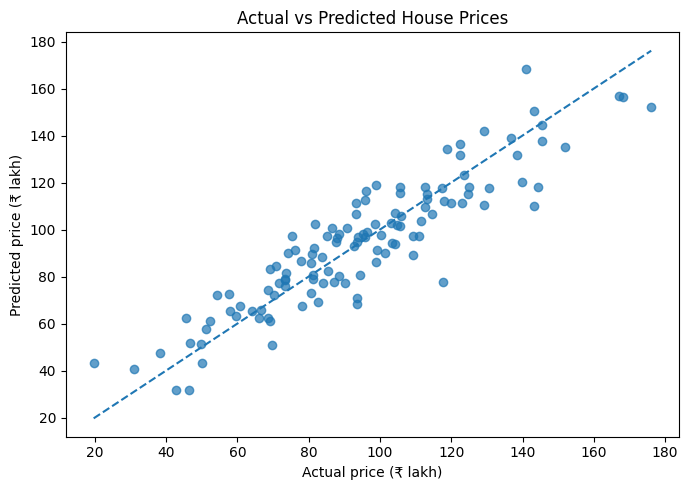

In [6]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred, alpha=.7)
lims=[min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "--")
plt.xlabel("Actual price (₹ lakh)"); plt.ylabel("Predicted price (₹ lakh)")
plt.title("Actual vs Predicted House Prices"); plt.tight_layout(); plt.show()

## 7. Residual diagnostics
Residual = actual − predicted. Look for systematic patterns, changing spread, and unusually large errors.

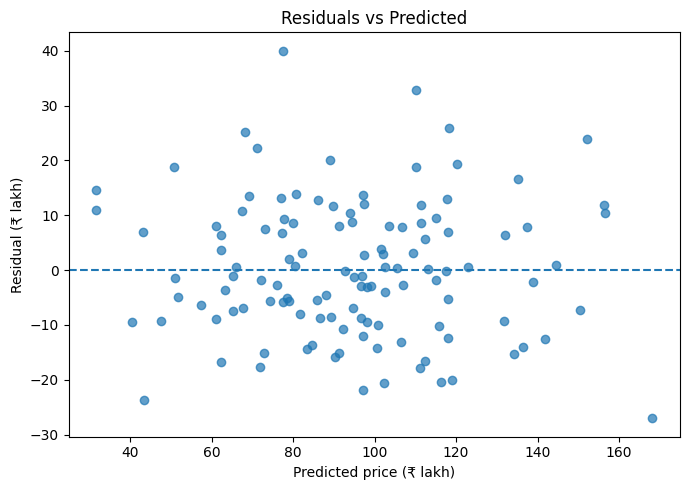

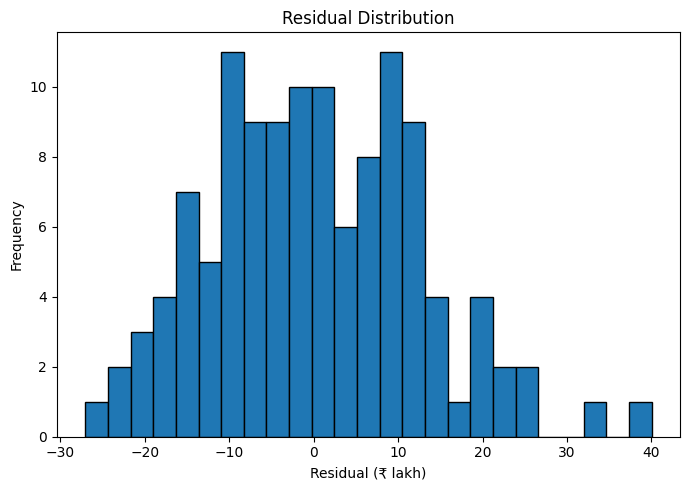

In [7]:
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(7,5))
plt.scatter(y_pred, residuals, alpha=.7); plt.axhline(0, linestyle="--")
plt.xlabel("Predicted price (₹ lakh)"); plt.ylabel("Residual (₹ lakh)")
plt.title("Residuals vs Predicted"); plt.tight_layout(); plt.show()

plt.figure(figsize=(7,5))
plt.hist(residuals, bins=25, edgecolor="black")
plt.xlabel("Residual (₹ lakh)"); plt.ylabel("Frequency")
plt.title("Residual Distribution"); plt.tight_layout(); plt.show()

## 8. Coefficients and conclusion
Because features are standardized, coefficients represent the change in predicted price associated with a one-standard-deviation increase in each feature, holding other inputs fixed. They are associations in this synthetic dataset, not causal effects.

In [8]:
coef_df = pd.DataFrame({
    "feature": FEATURES,
    "standardized_coefficient": pipeline.named_steps["model"].coef_
}).sort_values("standardized_coefficient", key=abs, ascending=False)
display(coef_df.round(3))
print("Conclusion: a multiple linear regression model was trained and evaluated on held-out data.")
print("Remember: the dataset is synthetic; metrics do not establish real-market accuracy.")

,feature,standardized_coefficient
0,area_sqft,22.457
3,property_age_years,-5.542
4,distance_to_city_km,-4.400
1,bedrooms,3.529
2,bathrooms,1.508
5,parking_spaces,1.117


Conclusion: a multiple linear regression model was trained and evaluated on held-out data.
Remember: the dataset is synthetic; metrics do not establish real-market accuracy.
